Język: [English](examples.en.ipynb) | **Polski**

# Wykład 09 — eksperyment: RNN, LSTM, GRU

Materiał towarzyszący [`lecture.md`](lecture.md). Cztery eksperymenty: (A) rozwinięcie
w czasie — ręczna komórka vs `nn.RNN`; (B) zanikający gradient — zmierzony, nie
założony; (C) zadanie zależne od kolejności tokenów; (D) bramki LSTM/GRU, kształty,
parametry, czas.


In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)  # stabilnosc watkow BLAS pod jupyter/ipykernel (lekcja z modulu 07)
device = torch.device("cpu")
print(f"Uzywane urzadzenie: {device}")

Uzywane urzadzenie: cpu


## A. Rozwinięcie RNN w czasie: ręczna komórka vs `nn.RNN`

Ten sam przykład liczbowy co w `lecture.md`: $d=2$, $d_h=2$, $T=3$.


In [2]:
d_in, d_h, T = 2, 2, 3

Wx = torch.tensor([[0.5, -0.3], [0.1, 0.8]])
Wh = torch.tensor([[0.2, 0.0], [-0.1, 0.4]])
b = torch.tensor([0.1, -0.1])

X = torch.tensor(
    [
        [1.0, 0.0],
        [0.0, 1.0],
        [1.0, 1.0],
    ]
)
h0 = torch.zeros(d_h)


def manual_rnn_forward(X, Wx, Wh, b, h0):
    """Recznie, podstawowymi operacjami - TA SAMA funkcja f(x_t, h_{t-1}) wywolana T razy."""
    h_prev = h0
    states = []
    for t in range(X.shape[0]):
        h_t = torch.tanh(Wx @ X[t] + Wh @ h_prev + b)
        states.append(h_t)
        h_prev = h_t
    return torch.stack(states)


manual_states = manual_rnn_forward(X, Wx, Wh, b, h0)
print("reczne stany ukryte h_1, h_2, h_3:")
print(manual_states)

reczne stany ukryte h_1, h_2, h_3:
tensor([[ 0.5370,  0.0000],
        [-0.0923,  0.5692],
        [ 0.2743,  0.7767]])


In [3]:
rnn = nn.RNN(input_size=d_in, hidden_size=d_h, num_layers=1, nonlinearity="tanh", batch_first=True)
with torch.no_grad():
    # PyTorch uzywa DWOCH oddzielnych biasow (b_ih, b_hh), sumowanych -
    # zobacz lecture.md. Ustawiamy b_ih=b, b_hh=0, zeby suma = nasz pojedynczy b.
    rnn.weight_ih_l0.copy_(Wx)
    rnn.weight_hh_l0.copy_(Wh)
    rnn.bias_ih_l0.copy_(b)
    rnn.bias_hh_l0.zero_()

out, h_n = rnn(X.unsqueeze(0), h0.view(1, 1, d_h))
print("nn.RNN stany ukryte:")
print(out.squeeze(0))

match = torch.allclose(manual_states, out.squeeze(0), atol=1e-6)
print(f"\nreczne == nn.RNN (tolerancja atol=1e-6): {match}")
assert match

nn.RNN stany ukryte:
tensor([[ 0.5370,  0.0000],
        [-0.0923,  0.5692],
        [ 0.2743,  0.7767]], grad_fn=<SqueezeBackward1>)

reczne == nn.RNN (tolerancja atol=1e-6): True


### Wpływ zmiany wcześniejszego elementu sekwencji na późniejsze stany

Zmieniamy TYLKO $x_1$ i sprawdzamy, które stany się zmieniają.


In [4]:
X_modified = X.clone()
X_modified[0] = torch.tensor([-1.0, -1.0])  # zmiana TYLKO pierwszego wejscia

states_original = manual_rnn_forward(X, Wx, Wh, b, h0)
states_modified = manual_rnn_forward(X_modified, Wx, Wh, b, h0)

for t in range(T):
    changed = not torch.allclose(states_original[t], states_modified[t], atol=1e-6)
    print(f"h_{t + 1}: zmieniony po modyfikacji x_1 = {changed}")

print(
    "\nWszystkie trzy stany sie zmienily - zmiana WCZESNIEJSZEGO wejscia wplywa na "
    "KAZDY pozniejszy stan (bo kazdy h_t zalezy od h_{t-1}, ktory zalezy od h_{t-2}, "
    "... az do x_1). To bezposrednia konsekwencja rekurencji, nie przypadek."
)

h_1: zmieniony po modyfikacji x_1 = True
h_2: zmieniony po modyfikacji x_1 = True
h_3: zmieniony po modyfikacji x_1 = True

Wszystkie trzy stany sie zmienily - zmiana WCZESNIEJSZEGO wejscia wplywa na KAZDY pozniejszy stan (bo kazdy h_t zalezy od h_{t-1}, ktory zalezy od h_{t-2}, ... az do x_1). To bezposrednia konsekwencja rekurencji, nie przypadek.


## B. Zanikający gradient — zmierzony, nie założony

Norma $\partial L/\partial x_1$ (strata = suma kwadratów ostatniego stanu
ukrytego) w funkcji długości sekwencji $T$, dla RNN, LSTM, GRU — **ten sam** $d_h$,
**ta sama** losowa inicjalizacja w każdym porównaniu (różne ziarna sprawdzone osobno).


In [5]:
def grad_wrt_first_input(model_type, T, d_in=4, d_h=8, seed=0):
    torch.manual_seed(seed)
    if model_type == "rnn":
        model = nn.RNN(d_in, d_h, batch_first=True)
    elif model_type == "lstm":
        model = nn.LSTM(d_in, d_h, batch_first=True)
    elif model_type == "gru":
        model = nn.GRU(d_in, d_h, batch_first=True)

    X_seq = torch.randn(1, T, d_in, requires_grad=True)
    out = model(X_seq)
    final_h = out[0][:, -1, :]
    loss = final_h.pow(2).sum()
    loss.backward()

    grad_x1_norm = X_seq.grad[0, 0].norm().item()
    grad_Whh_norm = model.weight_hh_l0.grad.norm().item()
    return grad_x1_norm, grad_Whh_norm


seq_lengths = [2, 5, 10, 20, 40, 80]
results = {"rnn": [], "lstm": [], "gru": []}
for T_val in seq_lengths:
    for name in results:
        g_x1, _ = grad_wrt_first_input(name, T_val)
        results[name].append(g_x1)

print(f"{'T':>4} {'RNN |grad x1|':>15} {'LSTM |grad x1|':>16} {'GRU |grad x1|':>15}")
for i, T_val in enumerate(seq_lengths):
    print(
        f"{T_val:>4} {results['rnn'][i]:>15.3e} {results['lstm'][i]:>16.3e} "
        f"{results['gru'][i]:>15.3e}"
    )

   T   RNN |grad x1|   LSTM |grad x1|   GRU |grad x1|
   2       4.777e-01        6.107e-02       1.588e-01
   5       1.186e-02        2.188e-03       1.136e-02
  10       9.774e-04        1.652e-03       1.976e-03
  20       2.798e-07        2.469e-06       1.059e-05
  40       2.677e-12        2.588e-10       2.988e-09
  80       0.000e+00        1.507e-17       1.167e-17


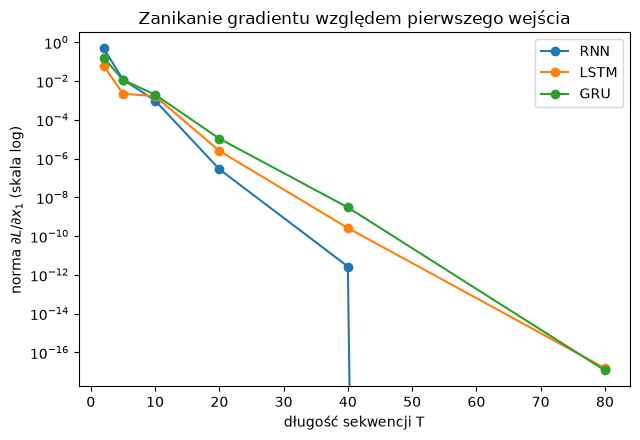

Wszystkie trzy architektury zanikaja do praktycznie zera przy wystarczajaco dlugiej sekwencji - LSTM/GRU NIE eliminuja problemu, spowalniaja go.


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, label in [("rnn", "RNN"), ("lstm", "LSTM"), ("gru", "GRU")]:
    ax.plot(seq_lengths, results[name], marker="o", label=label)
ax.set_yscale("log")
ax.set_xlabel("długość sekwencji T")
ax.set_ylabel("norma $\\partial L/\\partial x_1$ (skala log)")
ax.set_title("Zanikanie gradientu względem pierwszego wejścia")
ax.legend()
plt.tight_layout()
plt.show()

print(
    "Wszystkie trzy architektury zanikaja do praktycznie zera przy wystarczajaco "
    "dlugiej sekwencji - LSTM/GRU NIE eliminuja problemu, spowalniaja go."
)

**Czy LSTM/GRU zawsze mają większy gradient niż RNN?** Sprawdzamy na kilku ziarnach
przy $T=40$ — nie zakładamy odpowiedzi z góry.


In [7]:
print("seed   RNN          LSTM         GRU")
for seed in [0, 1, 2, 3, 4]:
    g_rnn, _ = grad_wrt_first_input("rnn", 40, seed=seed)
    g_lstm, _ = grad_wrt_first_input("lstm", 40, seed=seed)
    g_gru, _ = grad_wrt_first_input("gru", 40, seed=seed)
    print(f"{seed:>4}   {g_rnn:.3e}   {g_lstm:.3e}   {g_gru:.3e}")

seed   RNN          LSTM         GRU
   0   2.677e-12   2.588e-10   2.988e-09
   1   3.140e-14   2.133e-11   3.618e-09
   2   4.146e-14   1.868e-09   2.807e-10


   3   1.659e-14   2.371e-09   5.693e-09
   4   6.800e-16   3.114e-10   9.007e-08


### Inna wielkość: gradient względem współdzielonej macierzy $W_h$

To **nie** to samo co gradient względem $x_1$ — sumuje wkłady ze WSZYSTKICH kroków
czasowych, więc nawet gdy pojedyncze, odległe wkłady zanikają, bliskie kroki wciąż
dają zdrowy sygnał.


In [8]:
print(f"{'T':>4} {'RNN |grad W_hh|':>17} {'LSTM |grad W_hh|':>18} {'GRU |grad W_hh|':>17}")
for T_val in seq_lengths:
    _, w_rnn = grad_wrt_first_input("rnn", T_val)
    _, w_lstm = grad_wrt_first_input("lstm", T_val)
    _, w_gru = grad_wrt_first_input("gru", T_val)
    print(f"{T_val:>4} {w_rnn:>17.3e} {w_lstm:>18.3e} {w_gru:>17.3e}")

print(
    "\nW przeciwienstwie do gradientu wzgledem x_1 (ktory zanika o rzedy wielkosci), "
    "gradient wzgledem W_hh NIE maleje systematycznie z T - to inna wielkosc, z innym "
    "zachowaniem. Nie sa zamienne."
)

   T   RNN |grad W_hh|   LSTM |grad W_hh|   GRU |grad W_hh|
   2         1.925e+00          5.127e-02         9.850e-02
   5         1.821e+00          1.440e-01         3.667e-01
  10         2.418e+00          2.378e-01         5.776e-01
  20         2.248e+00          1.431e-01         4.536e-01
  40         1.844e+00          2.102e-01         7.063e-01
  80         3.202e+00          2.123e-01         3.892e-01

W przeciwienstwie do gradientu wzgledem x_1 (ktory zanika o rzedy wielkosci), gradient wzgledem W_hh NIE maleje systematycznie z T - to inna wielkosc, z innym zachowaniem. Nie sa zamienne.


## C. Zadanie zależne od kolejności tokenów

Sekwencje = permutacje TEGO SAMEGO zbioru 6 tokenów (identyczny bag-of-tokens w
każdej sekwencji) — etykieta zależy WYŁĄCZNIE od tego, czy token 0 pojawia się przed
tokenem 1. Baseline oparty na uśrednieniu embeddingów nie może mieć dostępu do tej
informacji (średnia jest niezmiennicza na permutacje wejścia).


In [9]:
VOCAB_SIZE, SEQ_LEN = 6, 6


def make_order_dataset(n, seed):
    g = torch.Generator().manual_seed(seed)
    seqs = torch.stack([torch.randperm(VOCAB_SIZE, generator=g) for _ in range(n)])
    pos0 = (seqs == 0).float().argmax(dim=1)
    pos1 = (seqs == 1).float().argmax(dim=1)
    labels = (pos0 < pos1).long()
    return seqs, labels


X_train, y_train = make_order_dataset(800, seed=0)
X_val, y_val = make_order_dataset(200, seed=1)
X_test, y_test = make_order_dataset(200, seed=2)

for seq in X_train[:20]:
    assert sorted(seq.tolist()) == list(range(VOCAB_SIZE)), "bag-of-tokens nie jest identyczny!"
print(f"train label balance: {y_train.float().mean():.3f} (powinno byc ok. 0.5)")
print("OK: kazda sekwencja to permutacja tego samego zbioru tokenow.")

train label balance: 0.512 (powinno byc ok. 0.5)
OK: kazda sekwencja to permutacja tego samego zbioru tokenow.


In [10]:
d_embed, d_hidden = 8, 16


class MeanPoolBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Embedding(VOCAB_SIZE, d_embed)
        self.fc = nn.Linear(d_embed, 2)

    def forward(self, x):
        e = self.embed(x)
        pooled = e.mean(dim=1)  # niezmiennicze na permutacje x
        return self.fc(pooled)


class SeqClassifier(nn.Module):
    def __init__(self, cell):
        super().__init__()
        self.embed = nn.Embedding(VOCAB_SIZE, d_embed)
        self.rnn = cell(d_embed, d_hidden, batch_first=True)
        self.fc = nn.Linear(d_hidden, 2)

    def forward(self, x):
        e = self.embed(x)
        out, _ = self.rnn(e)
        return self.fc(out[:, -1, :])


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def train_eval(model, epochs=30, lr=0.01, batch_size=32, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    n = X_train.shape[0]
    start = time.time()
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_train[idx]), y_train[idx])
            loss.backward()
            opt.step()
    train_time = time.time() - start
    model.eval()
    with torch.no_grad():
        val_acc = (model(X_val).argmax(1) == y_val).float().mean().item()
        test_acc = (model(X_test).argmax(1) == y_test).float().mean().item()
    return val_acc, test_acc, train_time


print(f"{'model':30s} {'params':>8s} {'val_acc':>8s} {'test_acc':>9s} {'czas':>7s}")
for name, build in [
    ("mean-pool (bez kolejnosci)", lambda: MeanPoolBaseline()),
    ("vanilla RNN", lambda: SeqClassifier(nn.RNN)),
    ("GRU", lambda: SeqClassifier(nn.GRU)),
]:
    m = build()
    n_params = count_params(m)
    val_acc, test_acc, t = train_eval(m)
    print(f"{name:30s} {n_params:>8d} {val_acc:>8.3f} {test_acc:>9.3f} {t:>6.2f}s")

model                            params  val_acc  test_acc    czas


mean-pool (bez kolejnosci)           66    0.450     0.505   0.10s


vanilla RNN                         498    1.000     1.000   0.23s


GRU                                1330    1.000     1.000   0.35s


**Interpretacja.** Baseline bez kolejności osiąga accuracy bliską przypadkowej —
**nie** z powodu mniejszej pojemności (zresztą ma mniej parametrów, co samo w sobie
nie jest przyczyną), tylko dlatego, że uśrednienie embeddingów jest **matematycznie
niezmiennicze** na kolejność tokenów wejściowych — informacja rozstrzygająca zadanie
jest dla niego **niedostępna z zasady**, niezależnie od budżetu treningu. RNN i GRU,
mając dostęp do kolejności, rozwiązują zadanie niemal perfekcyjnie.


## D. LSTM i GRU: bramki, kształty, parametry, czas


In [11]:
torch.manual_seed(0)
d_in_d, d_h_d, T_d = 3, 2, 4
X_d = torch.randn(1, T_d, d_in_d)

lstm = nn.LSTM(d_in_d, d_h_d, batch_first=True)
out_lstm, (hn_lstm, cn_lstm) = lstm(X_d)
print(f"LSTM: wejscie {tuple(X_d.shape)} -> wyjscie (wszystkie h_t) {tuple(out_lstm.shape)}")
print(f"  h_n (ostatni stan ukryty): {tuple(hn_lstm.shape)}")
print(f"  c_n (ostatni stan komorki): {tuple(cn_lstm.shape)}")

gru = nn.GRU(d_in_d, d_h_d, batch_first=True)
out_gru, hn_gru = gru(X_d)
print(f"\nGRU: wejscie {tuple(X_d.shape)} -> wyjscie {tuple(out_gru.shape)}")
print(f"  h_n: {tuple(hn_gru.shape)} (BRAK oddzielnego stanu komorki - GRU go nie ma)")

LSTM: wejscie (1, 4, 3) -> wyjscie (wszystkie h_t) (1, 4, 2)
  h_n (ostatni stan ukryty): (1, 1, 2)
  c_n (ostatni stan komorki): (1, 1, 2)

GRU: wejscie (1, 4, 3) -> wyjscie (1, 4, 2)
  h_n: (1, 1, 2) (BRAK oddzielnego stanu komorki - GRU go nie ma)


In [12]:
# reczna weryfikacja rownan bramek LSTM wzgledem nn.LSTM
W_ih, W_hh = lstm.weight_ih_l0, lstm.weight_hh_l0
b_ih, b_hh = lstm.bias_ih_l0, lstm.bias_hh_l0
W_ii, W_if, W_ig, W_io = W_ih.chunk(4, dim=0)
W_hi, W_hf, W_hg, W_ho = W_hh.chunk(4, dim=0)
b_ii, b_if, b_ig, b_io = b_ih.chunk(4, dim=0)
b_hi, b_hf, b_hg, b_ho = b_hh.chunk(4, dim=0)

h_prev, c_prev = torch.zeros(d_h_d), torch.zeros(d_h_d)
manual_h, manual_c = [], []
for t in range(T_d):
    x_t = X_d[0, t]
    i_t = torch.sigmoid(W_ii @ x_t + b_ii + W_hi @ h_prev + b_hi)
    f_t = torch.sigmoid(W_if @ x_t + b_if + W_hf @ h_prev + b_hf)
    g_t = torch.tanh(W_ig @ x_t + b_ig + W_hg @ h_prev + b_hg)
    o_t = torch.sigmoid(W_io @ x_t + b_io + W_ho @ h_prev + b_ho)
    c_t = f_t * c_prev + i_t * g_t
    h_t = o_t * torch.tanh(c_t)
    manual_h.append(h_t)
    manual_c.append(c_t)
    h_prev, c_prev = h_t, c_t

match_h = torch.allclose(torch.stack(manual_h), out_lstm.squeeze(0), atol=1e-6)
match_c = torch.allclose(c_prev, cn_lstm.squeeze(), atol=1e-6)
print(f"reczne rownania bramek LSTM == nn.LSTM: h: {match_h}, c: {match_c}")
assert match_h and match_c

reczne rownania bramek LSTM == nn.LSTM: h: True, c: True


In [13]:
# liczba parametrow i czas: RNN vs LSTM vs GRU, ten sam d_in/d_h
d_in_cmp, d_h_cmp, T_cmp, batch_cmp = 32, 64, 50, 64
X_cmp = torch.randn(batch_cmp, T_cmp, d_in_cmp)

print(f"{'model':8s} {'parametry':>10s} {'stosunek do RNN':>17s} {'czas forward (ms)':>19s}")
rnn_params = None
for name, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
    torch.manual_seed(0)
    m = cls(d_in_cmp, d_h_cmp, batch_first=True)
    n_params = sum(p.numel() for p in m.parameters())
    if name == "RNN":
        rnn_params = n_params
    start = time.time()
    with torch.no_grad():
        for _ in range(20):
            m(X_cmp)
    elapsed_ms = (time.time() - start) / 20 * 1000
    print(f"{name:8s} {n_params:>10d} {n_params / rnn_params:>16.1f}x {elapsed_ms:>18.2f}")

model     parametry   stosunek do RNN   czas forward (ms)
RNN            6272              1.0x               1.29
GRU           18816              3.0x               2.01
LSTM          25088              4.0x               3.18


## Podsumowanie

- Ręczna komórka RNN zgadza się z `nn.RNN` w granicach tolerancji numerycznej (`atol=1e-6`) — RNN to wielokrotne
  zastosowanie tej samej funkcji, zweryfikowane, nie zadeklarowane.
- Gradient względem pierwszego wejścia zanika wykładniczo z długością sekwencji dla
  wszystkich trzech architektur — LSTM/GRU spowalniają to zjawisko, nie eliminują.
  Gradient względem współdzielonych wag $W_h$ zachowuje się zupełnie inaczej.
- Baseline bez dostępu do kolejności jest matematycznie ograniczony do poziomu
  przypadku na zadaniu skonstruowanym tak, by kolejność była jedyną rozstrzygającą
  informacją — RNN/GRU rozwiązują je niemal perfekcyjnie.
- LSTM ma dokładnie $4\times$ parametrów RNN, GRU dokładnie $3\times$ — zweryfikowane,
  nie przybliżone.

Pytania do dyskusji i bibliografia: zobacz [`lecture.md`](lecture.md).
